<div style="background-color:#00264d; color:white; padding:16px; font-size:24px; font-weight:bold; border-radius:10px; text-align:center;">
  Specialized Quantum Encoding Schemes
</div>

<p style="font-size:20px; margin-top:12px; margin-left:10px;">
These encoding schemes are tailored for advanced quantum algorithms, quantum machine learning, and Hamiltonian simulation. They go beyond basic representations and leverage the structure of quantum circuits and mathematical functions.
</p>

<!-- 1 -->
<div style="background-color:#ffd6cc; color:#993300; padding:10px; font-weight:bold; font-size:20px; border-radius:8px;">1. Quantum Arbitrary Map Encoding</div>
<p style="margin-left:20px; font-size:20px;"><b style="color:#cc0000;">Motivation:</b> Encodes arbitrary functions/data points into quantum states using custom unitary transformations.</p>
<p style="margin-left:20px; color:#006400; font-size:20px;">✓ Advantage: Highly flexible and customizable to data structure.</p>
<p style="margin-left:20px; color:#8b0000; font-size:20px;">✗ Limitation: May require complex circuit design and high gate depth.</p>


In [ ]:
import numpy as np
from qiskit import QuantumCircuit
from qiskit_aer import Aer
from qiskit.compiler import transpile
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt

# Classical parameter (arbitrarily chosen)
a = 0.7  
# Map to state vector: [cos(a), sin(a)] (normalized already for our purpose)
state = [np.cos(a), np.sin(a)]

# Build circuit: initialize a single qubit with the state.
qc_arb = QuantumCircuit(1, 1)
qc_arb.initialize(state, 0)
qc_arb.measure(0, 0)



# Simulate on qasm simulator and plot histogram
backend = Aer.get_backend('qasm_simulator')
tqc_arb = transpile(qc_arb, backend)
job_arb = backend.run(tqc_arb, shots=1024)
counts_arb = job_arb.result().get_counts()




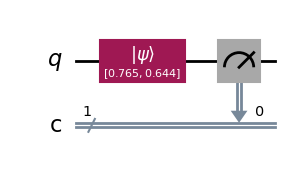

In [3]:
# Draw colored circuit diagram
qc_arb.draw(output='mpl')

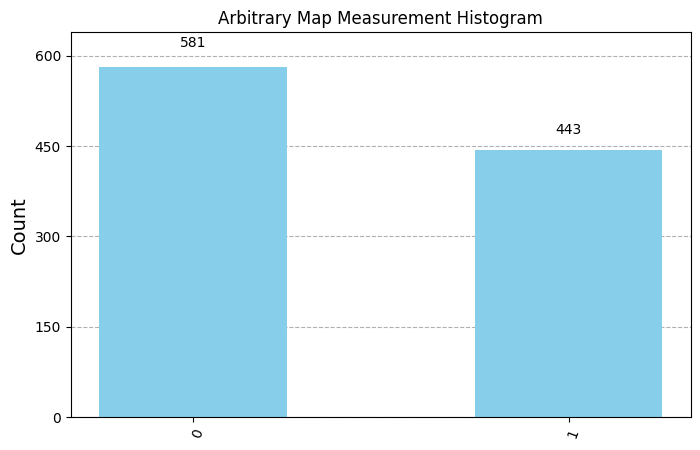

In [4]:
plot_histogram(counts_arb, color='skyblue', title="Arbitrary Map Measurement Histogram", figsize=(8,5))

<!-- 2 -->
<div style="background-color:#e6ffe6; color:#006600; padding:10px; font-weight:bold; font-size:20px; border-radius:8px;">2. Quantum Random Access Memory (QRAM) Encoding</div>
<p style="margin-left:20px; font-size:20px;"><b style="color:#cc0000;">Motivation:</b> Enables fast quantum access to large datasets via a binary tree structure.</p>
<p style="margin-left:20px; color:#006400; font-size:20px;">✓ Advantage: Efficient for loading and querying data in superposition.</p>
<p style="margin-left:20px; color:#8b0000; font-size:20px;">✗ Limitation: Requires sophisticated memory hardware; high decoherence sensitivity.</p>


In [5]:
import numpy as np
from qiskit import QuantumCircuit
from qiskit_aer import Aer
from qiskit.compiler import transpile
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt

# QRAM Encoding: 2 address qubits + 1 data qubit = 3 qubits total.
qc_qram = QuantumCircuit(3, 3)
# Put address qubits (q0 and q1) into superposition
qc_qram.h(0)
qc_qram.h(1)

# Conditioned on the address, apply rotations to the data qubit (q2).
# For simplicity, we apply a controlled-Ry from both addresses.
qc_qram.cry(np.pi/4, 0, 2)
qc_qram.cry(np.pi/3, 1, 2)

# Measure all qubits.
qc_qram.measure([0,1,2], [0,1,2])



# Simulation
backend = Aer.get_backend('qasm_simulator')
tqc_qram = transpile(qc_qram, backend)
job_qram = backend.run(tqc_qram, shots=1024)
counts_qram = job_qram.result().get_counts()


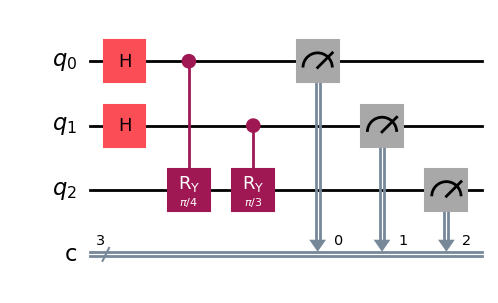

In [6]:
# Draw circuit.
qc_qram.draw(output='mpl')

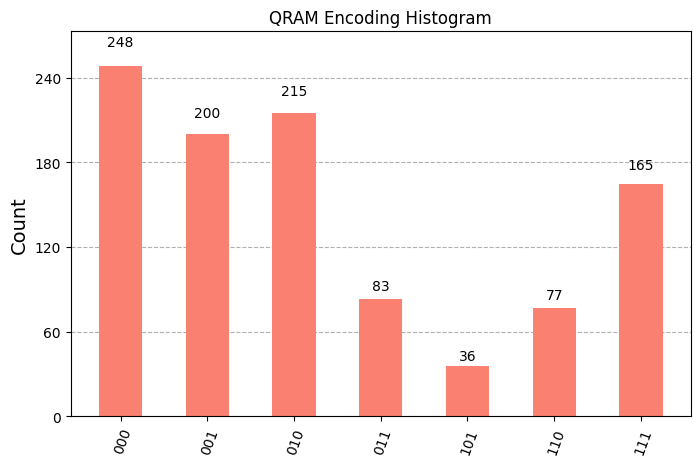

In [7]:

plot_histogram(counts_qram, color='salmon', title="QRAM Encoding Histogram", figsize=(8,5))


<!-- 3 -->
<div style="background-color:#ffe6f0; color:#99004d; padding:10px; font-weight:bold; font-size:20px; border-radius:8px;">3. Variational Encoding</div>
<p style="margin-left:20px; font-size:20px;"><b style="color:#cc0000;">Motivation:</b> Encodes data using trainable parameters within quantum circuits.</p>
<p style="margin-left:20px; color:#006400; font-size:20px;">✓ Advantage: Supports learning optimal embeddings directly from data.</p>
<p style="margin-left:20px; color:#8b0000; font-size:20px;">✗ Limitation: Requires classical-quantum hybrid training; may suffer from barren plateaus.</p>


In [8]:
from qiskit import QuantumCircuit
from qiskit_aer import Aer
from qiskit.compiler import transpile
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt

# Classical data (parameters)
theta1 = 0.8
theta2 = 1.2

# Build a 2-qubit variational encoding circuit.
qc_var = QuantumCircuit(2, 2)
qc_var.ry(theta1, 0)
qc_var.ry(theta2, 1)
# Add an entangling layer
qc_var.cx(0, 1)
# Measure both qubits.
qc_var.measure([0,1], [0,1])



backend = Aer.get_backend('qasm_simulator')
tqc_var = transpile(qc_var, backend)
job_var = backend.run(tqc_var, shots=1024)
counts_var = job_var.result().get_counts()





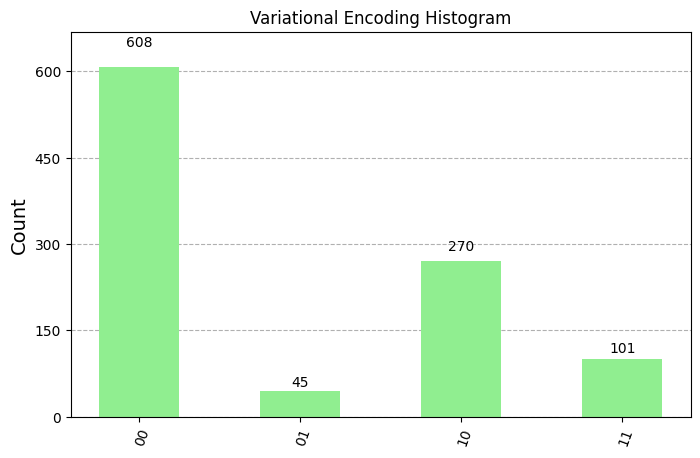

In [9]:
plot_histogram(counts_var, color='lightgreen', title="Variational Encoding Histogram", figsize=(8,5))

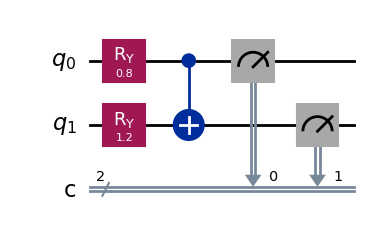

In [10]:
qc_var.draw(output='mpl')

<!-- 4 -->
<div style="background-color:#ccf2ff; color:#005580; padding:10px; font-weight:bold; font-size:20px; border-radius:8px;">4. Chebyshev Encoding</div>
<p style="margin-left:20px; font-size:20px;"><b style="color:#cc0000;">Motivation:</b> Uses Chebyshev polynomials to approximate functions inside quantum states.</p>
<p style="margin-left:20px; color:#006400; font-size:20px;">✓ Advantage: Useful for function approximation and Hamiltonian simulation.</p>
<p style="margin-left:20px; color:#8b0000; font-size:20px;">✗ Limitation: Implementation is mathematically involved and application-specific.</p>


In [11]:
import numpy as np
from qiskit import QuantumCircuit
from qiskit_aer import Aer
from qiskit.compiler import transpile
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt

# Classical data value
x = 0.6
# Chebyshev polynomials: T0 = 1, T1 = x
state = [1, x]
# Normalize the state
norm = np.sqrt(1 + x**2)
state = [v/norm for v in state]

qc_cheb = QuantumCircuit(1,1)
qc_cheb.initialize(state, 0)
qc_cheb.measure(0,0)


backend = Aer.get_backend('qasm_simulator')
tqc_cheb = transpile(qc_cheb, backend)
job_cheb = backend.run(tqc_cheb, shots=1024)
counts_cheb = job_cheb.result().get_counts()



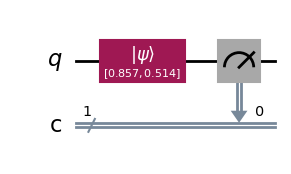

In [12]:
qc_cheb.draw(output='mpl')

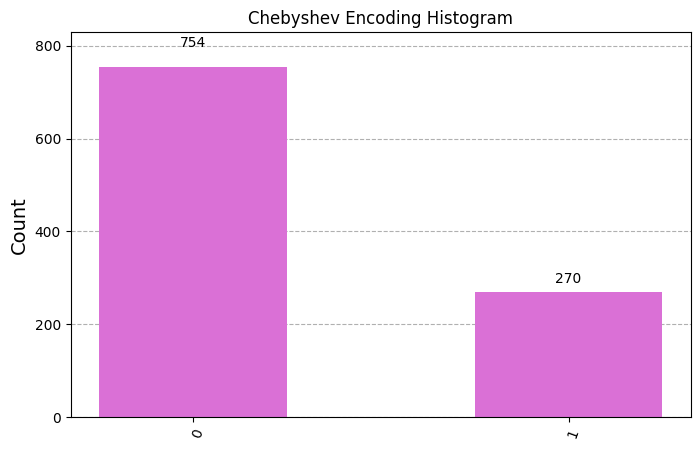

In [13]:
plot_histogram(counts_cheb, color='orchid', title="Chebyshev Encoding Histogram", figsize=(8,5))

<!-- 5 -->
<div style="background-color:#fff0b3; color:#805500; padding:10px; font-weight:bold; font-size:20px; border-radius:8px;">5. Fourier Encoding</div>
<p style="margin-left:20px; font-size:20px;"><b style="color:#cc0000;">Motivation:</b> Encodes signals or functions using quantum Fourier transform (QFT).</p>
<p style="margin-left:20px; color:#006400; font-size:20px;">✓ Advantage: Very efficient for periodic or frequency-domain problems.</p>
<p style="margin-left:20px; color:#8b0000; font-size:20px;">✗ Limitation: Requires exact gate implementation and periodic inputs.</p>


In [14]:
from qiskit import QuantumCircuit
from qiskit_aer import Aer
from qiskit.compiler import transpile
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt

# Classical data: frequency or phase parameter
phi = 1.0  # in radians

qc_fourier = QuantumCircuit(1, 1)
# Start in |+> by applying Hadamard
qc_fourier.h(0)
# Encode the classical data by applying a phase gate.
qc_fourier.p(phi, 0)
qc_fourier.measure(0, 0)

backend = Aer.get_backend('qasm_simulator')
tqc_fourier = transpile(qc_fourier, backend)
job_fourier = backend.run(tqc_fourier, shots=1024)
counts_fourier = job_fourier.result().get_counts()

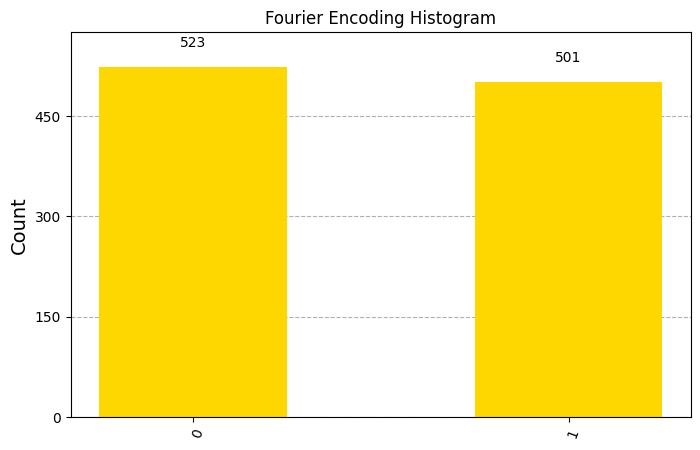

In [15]:
plot_histogram(counts_fourier, color='gold', title="Fourier Encoding Histogram", figsize=(8,5))

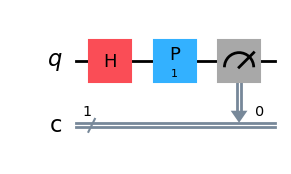

In [16]:
qc_fourier.draw(output='mpl')

<!-- 6 -->
<div style="background-color:#e0e0eb; color:#333366; padding:10px; font-weight:bold; font-size:20px; border-radius:8px;">6. Projected Unitary Encoding</div>
<p style="margin-left:20px; font-size:20px;"><b style="color:#cc0000;">Motivation:</b> Encodes matrix elements of a Hermitian operator as projections of unitary matrices.</p>
<p style="margin-left:20px; color:#006400; font-size:20px;">✓ Advantage: Enables simulation of quantum operators within block structures.</p>
<p style="margin-left:20px; color:#8b0000; font-size:20px;">✗ Limitation: Requires ancilla qubits and careful projection mechanisms.</p>


In [17]:
import numpy as np
from qiskit import QuantumCircuit
from qiskit_aer import Aer
from qiskit.compiler import transpile
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt

# Use 2 qubits: one ancilla and one data qubit.
qc_proj = QuantumCircuit(2, 2)
# Prepare ancilla in superposition
qc_proj.h(0)
# Apply a controlled-Ry gate: if ancilla=1, rotate data qubit.
qc_proj.cry(np.pi/3, 0, 1)
qc_proj.measure([0,1], [0,1])


backend = Aer.get_backend('qasm_simulator')
tqc_proj = transpile(qc_proj, backend)
job_proj = backend.run(tqc_proj, shots=1024)
counts_proj = job_proj.result().get_counts()



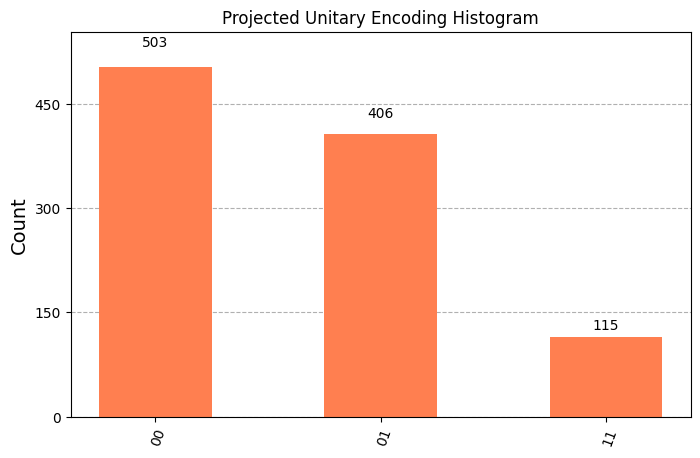

In [18]:
plot_histogram(counts_proj, color='coral', title="Projected Unitary Encoding Histogram", figsize=(8,5))

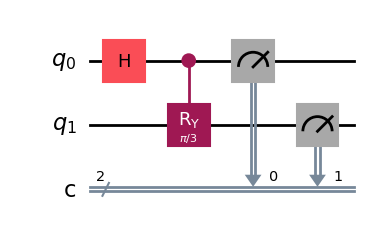

In [19]:
qc_proj.draw(output='mpl')

<!-- 7 -->
<div style="background-color:#f2d9e6; color:#660033; padding:10px; font-weight:bold; font-size:20px; border-radius:8px;">7. Block Encoding</div>
<p style="margin-left:20px; font-size:20px;"><b style="color:#cc0000;">Motivation:</b> Embeds matrices (e.g., Hamiltonians) into larger unitary matrices for simulation.</p>
<p style="margin-left:20px; color:#006400; font-size:20px;">✓ Advantage: Foundation for Hamiltonian simulation and quantum linear algebra (e.g., HHL algorithm).</p>
<p style="margin-left:20px; color:#8b0000; font-size:20px;">✗ Limitation: Requires additional space (ancillas) and quantum control logic.</p>


In [20]:
import numpy as np
from qiskit import QuantumCircuit
from qiskit_aer import Aer
from qiskit.compiler import transpile
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt

# Block Encoding: 2 qubits with one ancilla.
qc_block = QuantumCircuit(2, 2)
# Prepare ancilla in |+> state
qc_block.h(0)
# Apply controlled rotation on data qubit (q1)
qc_block.cx(0, 1)
qc_block.ry(np.pi/4, 1)
qc_block.cx(0, 1)
qc_block.measure([0,1], [0,1])


backend = Aer.get_backend('qasm_simulator')
tqc_block = transpile(qc_block, backend)
job_block = backend.run(tqc_block, shots=1024)
counts_block = job_block.result().get_counts()



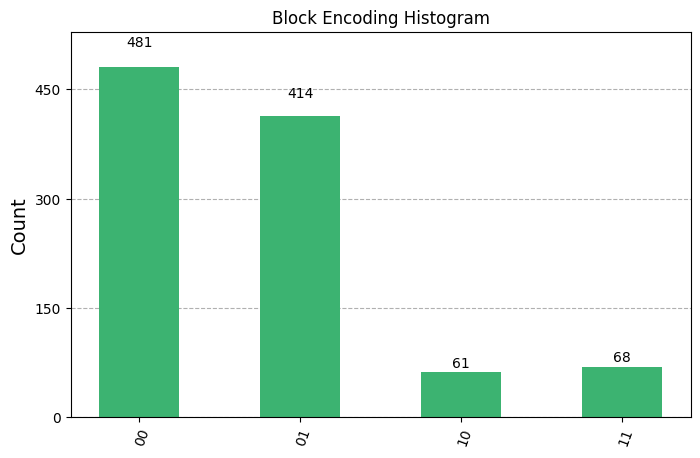

In [21]:
plot_histogram(counts_block, color='mediumseagreen', title="Block Encoding Histogram", figsize=(8,5))

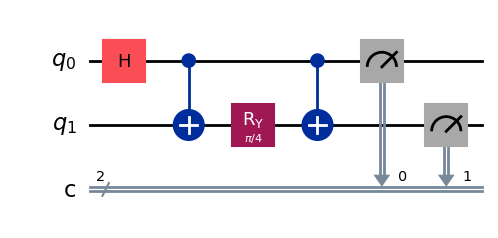

In [22]:
qc_block.draw(output='mpl')
